# Análisis de Biomasa Residual Agrícola en Argentina

**Objetivo**: Estimar la biomasa residual generada por los principales cultivos extensivos a nivel departamental, integrando dos fuentes oficiales: la Bolsa de Cereales de Córdoba (CBA) y las Estimaciones Agrícolas del Ministerio de Agricultura, Ganadería y Pesca de la Nación (MAGYP).

**Estructura narrativa del análisis**:

| Fase | Descripción |
|------|-------------|
| **1. Exploración** | Ingesta de fuentes, diagnóstico de estructura, dominios y calidad. |
| **2. Conclusiones y acciones** | Síntesis de hallazgos y plan de acciones a implementar. |
| **3. Desarrollo** | Implementación de las acciones: normalización, taxonomía, reconciliación. |
| **4. Pruebas y mediciones** | Verificación de invariantes y cuantificación del impacto. |

In [19]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import geopandas as gpd
import pytest

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Fase 1 — Exploración

En esta fase se caracteriza la estructura, los dominios y la calidad de las dos fuentes primarias sin aplicar transformaciones. El objetivo es producir evidencia suficiente para decidir qué acciones de limpieza y reconciliación son necesarias.

## 1.1 Ingesta de fuentes primarias

Se cargan ambos datasets en su forma cruda. El dataset de la Bolsa de Cereales de Buenos Aires fue descartado por utilizar la zonificación PAS en lugar de la división administrativa departamental, incompatible con la granularidad requerida.

In [20]:
df_bolsa_cereales_cba = pd.read_csv("./../data/raw/datos_bolsa_granos_cba.csv")
df_estimaciones_agricolas = pd.read_csv(
    "./../data/raw/datos_estimaciones.csv", encoding="utf-8-sig"
)
df_IC = pd.read_csv("./../data/reference/ic_fr.csv")

## 1.2 Diagnóstico de estructura

Se inspecciona la forma, tipos y cobertura de nulos de cada fuente. Esto permite identificar problemas de calidad antes de cualquier transformación.

In [21]:
print("================ BOLSA DE CEREALES CBA ================")
print(df_bolsa_cereales_cba.info())
print("\n================ MAGYP ESTIMACIONES ================")
print(df_estimaciones_agricolas.info())

================ BOLSA DE CEREALES CBA ================
<class 'pandas.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   PROVINCIA                        4094 non-null   str    
 1   DEPARTAMENTO                     4094 non-null   str    
 2   CULTIVO                          4094 non-null   str    
 3   CAMPAÑA                          4094 non-null   str    
 4   SEMBRADAS                        4094 non-null   float64
 5   COSECHADAS                       4094 non-null   float64
 6   RENDIMIENTO                      3850 non-null   float64
 7   RENDIMIENTO GRANO LIMPIO Y SECO  215 non-null    float64
 8   PRODUCCIÓN                       3850 non-null   float64
 9   PRODUCCIÓN GRANO LIMPIO Y SECO   215 non-null    float64
dtypes: float64(6), str(4)
memory usage: 448.7 KB
None

================ MAGYP ESTIMACIONES ============

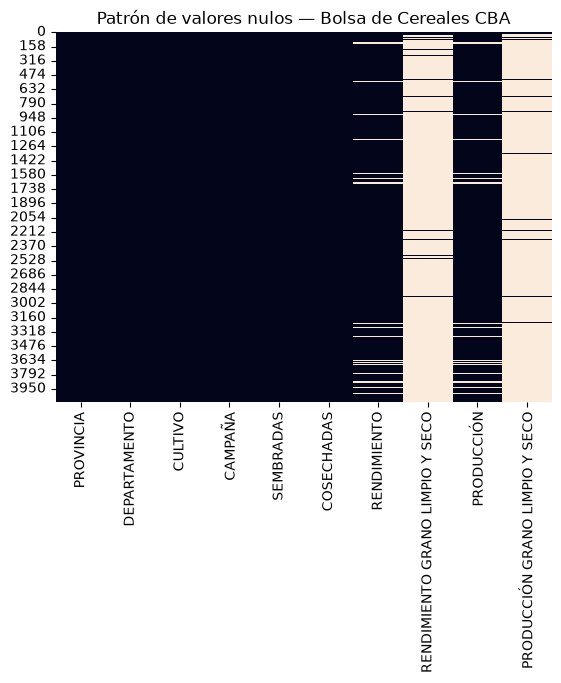

In [22]:
sns.heatmap(df_bolsa_cereales_cba.isnull(), cbar=False)
plt.title("Patrón de valores nulos — Bolsa de Cereales CBA")
plt.show()

## 1.3 Exploración de dominios categóricos

Se listan los valores únicos de las columnas `Cultivo`, `Provincia` y `Departamento` en cada fuente, para detectar variabilidad ortográfica, abreviaturas y agregados (`X total`).

In [23]:
print("Cultivos crudos CBA ({} únicos):".format(df_bolsa_cereales_cba["CULTIVO"].nunique()))
print(sorted(df_bolsa_cereales_cba["CULTIVO"].unique()))

print("\nProvincias CBA:", sorted(df_bolsa_cereales_cba["PROVINCIA"].unique()))

deptos_cba = sorted(df_bolsa_cereales_cba["DEPARTAMENTO"].unique())
print(f"\nDepartamentos CBA: {len(deptos_cba)} únicos. Muestra:")
print(deptos_cba[:10], "...")

Cultivos crudos CBA (10 únicos):
['ALFALFA', 'GARBANZO', 'GIRASOL', 'MAIZ', 'MANI', 'SOJA', 'SORGO', 'SORGO ', 'TRIGO', 'TRIGO CANDEAL']

Provincias CBA: ['Buenos Aires', 'Catamarca', 'Córdoba', 'La Pampa', 'San Luis', 'Santiago del Estero', 'Tucumán']

Departamentos CBA: 124 únicos. Muestra:
['25 DE MAYO', '9 DE JULIO', 'ADOLFO ALSINA', 'AGUIRRE', 'ALBERDI', 'AMBATO', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'BANDA'] ...


In [24]:
print("Cultivos crudos MAGYP ({} únicos):".format(df_estimaciones_agricolas["Cultivo"].nunique()))
print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

print("\nProvincias MAGYP:", df_estimaciones_agricolas["Provincia"].nunique(), "únicas")
print("Departamentos MAGYP:", df_estimaciones_agricolas["Departamento"].nunique(), "únicos")

Cultivos crudos MAGYP (41 únicos):
['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']

Provincias MAGYP: 23 únicas
Departamentos MAGYP: 410 únicos


## 1.4 Diagnóstico de solapamiento entre fuentes

Se cuantifica cuántas claves naturales `(Provincia, Departamento, Campaña, Cultivo)` estarán potencialmente cubiertas por ambas fuentes. Esto determina si el problema de doble conteo es relevante.

In [25]:
prov_cba = set(df_bolsa_cereales_cba["PROVINCIA"].str.strip().str.lower())
prov_magyp = set(df_estimaciones_agricolas["Provincia"].str.strip().str.lower())

print(f"Provincias CBA: {len(prov_cba)} | MAGYP: {len(prov_magyp)}")
print(f"Intersección de provincias: {sorted(prov_cba & prov_magyp)}")

Provincias CBA: 7 | MAGYP: 23
Intersección de provincias: ['buenos aires', 'catamarca', 'la pampa', 'san luis', 'santiago del estero']


## 1.5 Conclusiones de la exploración


De los diagnósticos anteriores se derivan los siguientes hallazgos:

**H1 — Cobertura geográfica asimétrica**. MAGYP cubre 23 provincias; CBA cubre 7. Existe intersección parcial entre ambas, lo que genera riesgo de doble conteo al integrar sin política de reconciliación.

**H2 — Inconsistencia léxica en cultivos**. CBA usa mayúsculas (`MAIZ`, `SOJA`, `SORGO `); MAGYP usa capitalización tipo título (`Maíz`, `Soja`, `Sorgo`). Además, CBA presenta espacios residuales (`SORGO `) y MAGYP utiliza sufijos `total` para agregados.

**H3 — Estructura agregado/componente**. MAGYP reporta simultáneamente registros agregados (`Soja total`, `Cebada total`) y sus componentes (`Soja 1ra`, `Soja 2da`, `Cebada cervecera`, `Cebada forrajera`). Sumar sin resolver genera doble conteo.

**H4 — Inconsistencia en nomenclatura de departamentos**. CBA presenta abreviaturas (`GRAL PEDERNERA`, `J.B.ALBERDI`) y variabilidad en puntuación (`LEANDRO N ALEM`, `LEANDRO N. ALEM`), mientras que MAGYP usa nombres completos (`GENERAL PEDERNERA`, `JUAN B. ALBERDI`).

**H5 — Columnas con cobertura marginal**. CBA tiene `RENDIMIENTO GRANO LIMPIO Y SECO` y `PRODUCCIÓN GRANO LIMPIO Y SECO` con cobertura ~5% (215/4094). Representan sub-categorías específicas, no la variable principal.

**H6 — Tipo de datos incorrecto en MAGYP**. Las columnas numéricas (`Sup. Sembrada`, `Sup. Cosechada`, `Producción`, `Rendimiento`) están codificadas como `str`.

**H7 — Índices de cosecha no cubren todos los cultivos**. La tabla de referencia IC tiene 17 entradas; MAGYP reporta 33 cultivos canónicos. Los cultivos sin IC documentado no pueden procesarse.

# Fase 2 — Conclusiones y plan de acciones

Las conclusiones de la Fase 1 derivan en un conjunto explícito de acciones a implementar en la Fase 3. Cada acción responde a uno o más hallazgos.

| Acción | Hallazgo que resuelve | Descripción |
|--------|----------------------|-------------|
| **A1** | H2 | Normalización léxica determinística de strings (NFKD, ASCII, lowercase, colapso de espacios). |
| **A2** | H3 | Definición de taxonomía canónica con marca de agregado y componentes declarados. |
| **A3** | H4 | Normalización geográfica con diccionario de abreviaturas y alias por provincia. |
| **A4** | H3 | Resolución de coexistencia agregado/componente por clave natural (prevalece agregado). |
| **A5** | H1 | Política de reconciliación multi-fuente por mayor producción declarada. |
| **A6** | H5 | Eliminación justificada de columnas de cobertura marginal en CBA. |
| **A7** | H6 | Conversión de tipos numéricos con reporte de coerción. |
| **A8** | H7 | Manejo explícito de cultivos sin IC mediante flags de validez (no `dropna`). |

**Política de reconciliación multi-fuente (POL-SOURCE-001)**: en claves cubiertas simultáneamente por CBA y MAGYP, prevalece el registro con mayor producción declarada, fundado en la naturaleza jurídica de los datos declarados ante AFIP en el marco del SISA (Resolución General Conjunta MAGyP y AFIP 5236). Los registros descartados se preservan en datasets de auditoría.

# Fase 3 — Desarrollo de acciones

Implementación de las acciones A1–A8 definidas en la Fase 2.

## 3.1 A1 — Normalización léxica

Función idempotente: NFKD → ASCII → colapso de whitespace → lowercase → strip.

In [26]:
def clean_str(s: str) -> str:
    """Normaliza strings para matching determinístico entre fuentes."""
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFKD", s)
    s = s.encode("ascii", "ignore").decode("ascii")
    s = re.sub(r"\s+", " ", s)
    return s.strip().lower()

## 3.2 A3 — Normalización geográfica

Pipeline en cuatro etapas: normalización léxica, remoción de puntos, expansión de abreviaturas, resolución de alias por `(provincia, departamento)`.

In [27]:
def strip_periods(s: str) -> str:
    if not isinstance(s, str):
        return s
    return re.sub(r"\s+", " ", s.replace(".", " ")).strip()


ABBREV_SAFE = {
    "gral": "general", "pte": "presidente", "gob": "gobernador",
    "dr": "doctor", "dra": "doctora", "cnl": "coronel",
    "tte": "teniente", "sgt": "sargento", "cap": "capitan",
}


def expand_abbrevs(s: str, mapping: dict = ABBREV_SAFE) -> str:
    if not isinstance(s, str):
        return s
    return " ".join(mapping.get(tok, tok) for tok in s.split(" "))


DEPT_ALIASES = {
    ("tucuman",             "j b alberdi"):  "juan b alberdi",
    ("santiago del estero", "j f ibarra"):   "juan felipe ibarra",
}


def resolve_dept_alias(provincia: str, dept: str, aliases: dict = DEPT_ALIASES) -> str:
    return aliases.get((provincia, dept), dept)


def normalize_geo(
    df: pd.DataFrame,
    prov_col: str = "Provincia",
    dept_col: str = "Departamento",
    aliases: dict = DEPT_ALIASES,
) -> pd.DataFrame:
    df = df.copy()
    df[prov_col] = df[prov_col].apply(clean_str)
    df[dept_col] = (
        df[dept_col].apply(clean_str).apply(strip_periods).apply(expand_abbrevs)
    )
    df[dept_col] = [
        resolve_dept_alias(p, d, aliases) for p, d in zip(df[prov_col], df[dept_col])
    ]
    return df


def flag_invalid_geo(df: pd.DataFrame, dept_col: str = "Departamento") -> pd.DataFrame:
    df = df.copy()
    df["_dept_valido"] = ~df[dept_col].isin({"sin definir", "", "na", "n/a"})
    return df

## 3.3 A2 — Taxonomía canónica de cultivos

Tabla declarativa que mapea nombres raw a nombres canónicos, con marca de agregado y componentes. Reglas:

- Nombres compuestos (`caña de azúcar`, `yerba mate`) no se colapsan.
- Cultivos biológicamente distintos (`trigo candeal` vs `trigo`) se preservan separados.
- Nombres base canónicos (`soja`, `trigo`, `cebada`, `poroto`, `papa`, `cebolla`) se incluyen explícitamente.
- Falla bloqueante (`fail-fast`) ante entradas no mapeadas.

In [28]:
CROP_TAXONOMY = {
    # Familia soja
    "soja":       {"canonical": "soja",   "is_aggregate": False},
    "soja 1ra":   {"canonical": "soja",   "is_aggregate": False},
    "soja 2da":   {"canonical": "soja",   "is_aggregate": False},
    "soja total": {"canonical": "soja",   "is_aggregate": True},
    # Familia cebada
    "cebada":           {"canonical": "cebada", "is_aggregate": False},
    "cebada cervecera": {"canonical": "cebada", "is_aggregate": False},
    "cebada forrajera": {"canonical": "cebada", "is_aggregate": False},
    "cebada total":     {"canonical": "cebada", "is_aggregate": True},
    # Familia poroto
    "poroto":        {"canonical": "poroto", "is_aggregate": False},
    "poroto alubia": {"canonical": "poroto", "is_aggregate": False},
    "poroto negro":  {"canonical": "poroto", "is_aggregate": False},
    "poroto otros":  {"canonical": "poroto", "is_aggregate": False},
    "poroto total":  {"canonical": "poroto", "is_aggregate": True},
    # Totales sin breakdown
    "trigo":         {"canonical": "trigo",   "is_aggregate": False},
    "trigo total":   {"canonical": "trigo",   "is_aggregate": True},
    "papa":          {"canonical": "papa",    "is_aggregate": False},
    "papa total":    {"canonical": "papa",    "is_aggregate": True},
    "cebolla":       {"canonical": "cebolla", "is_aggregate": False},
    "cebolla total": {"canonical": "cebolla", "is_aggregate": True},
    # Compuestos / biológicamente distintos
    "trigo candeal":  {"canonical": "trigo candeal",  "is_aggregate": False},
    "cana de azucar": {"canonical": "cana de azucar", "is_aggregate": False},
    "yerba mate":     {"canonical": "yerba mate",     "is_aggregate": False},
    # Cultivos simples
    "ajo":       {"canonical": "ajo",      "is_aggregate": False},
    "algodon":   {"canonical": "algodon",  "is_aggregate": False},
    "alpiste":   {"canonical": "alpiste",  "is_aggregate": False},
    "arroz":     {"canonical": "arroz",    "is_aggregate": False},
    "arveja":    {"canonical": "arveja",   "is_aggregate": False},
    "avena":     {"canonical": "avena",    "is_aggregate": False},
    "banana":    {"canonical": "banana",   "is_aggregate": False},
    "cartamo":   {"canonical": "cartamo",  "is_aggregate": False},
    "centeno":   {"canonical": "centeno",  "is_aggregate": False},
    "colza":     {"canonical": "colza",    "is_aggregate": False},
    "garbanzo":  {"canonical": "garbanzo", "is_aggregate": False},
    "girasol":   {"canonical": "girasol",  "is_aggregate": False},
    "jojoba":    {"canonical": "jojoba",   "is_aggregate": False},
    "lenteja":   {"canonical": "lenteja",  "is_aggregate": False},
    "limon":     {"canonical": "limon",    "is_aggregate": False},
    "lino":      {"canonical": "lino",     "is_aggregate": False},
    "maiz":      {"canonical": "maiz",     "is_aggregate": False},
    "mandarina": {"canonical": "mandarina","is_aggregate": False},
    "mani":      {"canonical": "mani",     "is_aggregate": False},
    "mijo":      {"canonical": "mijo",     "is_aggregate": False},
    "naranja":   {"canonical": "naranja",  "is_aggregate": False},
    "pomelo":    {"canonical": "pomelo",   "is_aggregate": False},
    "sorgo":     {"canonical": "sorgo",    "is_aggregate": False},
    "te":        {"canonical": "te",       "is_aggregate": False},
    "tung":      {"canonical": "tung",     "is_aggregate": False},
}

## 3.4 A4 — Resolución de agregados vs componentes

Función pura que, por clave natural `(Campaña, Provincia, Departamento, cultivo_canónico)`, conserva únicamente los registros agregados si coexisten con componentes. Preserva trazabilidad en `_source_cultivo`.

In [29]:
def resolve_crops(
    df: pd.DataFrame,
    taxonomy: dict,
    raw_col: str = "Cultivo",
    keys: tuple = ("Campaña", "Provincia", "Departamento"),
) -> pd.DataFrame:
    df = df.copy()
    unmapped = sorted(set(df[raw_col].unique()) - set(taxonomy.keys()))
    if unmapped:
        raise ValueError(
            f"Cultivos sin mapeo en CROP_TAXONOMY: {unmapped}. "
            "Agregar explícitamente antes de continuar."
        )
    meta = df[raw_col].map(taxonomy)
    df["_canonical"]    = meta.map(lambda x: x["canonical"])
    df["_is_aggregate"] = meta.map(lambda x: x["is_aggregate"])

    gkey = list(keys) + ["_canonical"]
    df["_has_aggregate"] = (
        df.groupby(gkey, dropna=False)["_is_aggregate"].transform("any")
    )
    keep_mask = (~df["_has_aggregate"]) | (df["_is_aggregate"])
    resolved = df.loc[keep_mask].copy()
    resolved["_source_cultivo"] = resolved[raw_col]
    resolved = resolved.drop(columns=[raw_col, "_is_aggregate", "_has_aggregate"])
    resolved = resolved.rename(columns={"_canonical": "Cultivo"})
    return resolved.reset_index(drop=True)

## 3.5 A6 — Limpieza CBA

Se descartan las columnas de grano limpio y seco por cobertura marginal (~5%) y se eliminan filas con nulos residuales (que coinciden con nulos en Producción y Rendimiento por definición).

In [30]:
df_bolsa_cereales_cba_cleaned = (
    df_bolsa_cereales_cba
    .drop(columns=["RENDIMIENTO GRANO LIMPIO Y SECO", "PRODUCCIÓN GRANO LIMPIO Y SECO"])
    .dropna()
)
df_bolsa_cereales_cba_cleaned.info()

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 393.5 KB


## 3.6 Aplicación del pipeline a CBA

Se aplican A1 (léxica), A3 (geográfica), A4 (resolución de cultivos). Se descarta `_dept_valido` (todos válidos en CBA).

In [31]:
df_cba = df_bolsa_cereales_cba_cleaned.rename(columns={
    "PROVINCIA": "Provincia", "DEPARTAMENTO": "Departamento",
    "CULTIVO": "Cultivo", "CAMPAÑA": "Campaña",
})
df_cba["Cultivo"] = df_cba["Cultivo"].apply(clean_str)
df_cba = normalize_geo(df_cba)
df_cba = flag_invalid_geo(df_cba)
df_cba_resolved = resolve_crops(df_cba, CROP_TAXONOMY)
df_cba_resolved = df_cba_resolved.drop(columns=["_dept_valido"])

print("Cultivos canónicos CBA:", sorted(df_cba_resolved["Cultivo"].unique()))
print(f"Registros: {len(df_cba_resolved):,}")

Cultivos canónicos CBA: ['garbanzo', 'girasol', 'maiz', 'mani', 'soja', 'sorgo', 'trigo', 'trigo candeal']
Registros: 3,850


## 3.7 Aplicación del pipeline a MAGYP

In [32]:
df_magyp = df_estimaciones_agricolas.copy()
df_magyp["Cultivo"] = df_magyp["Cultivo"].apply(clean_str)
df_magyp = normalize_geo(df_magyp)
df_magyp = flag_invalid_geo(df_magyp)
df_est_resolved = resolve_crops(df_magyp, CROP_TAXONOMY)
df_est_resolved = df_est_resolved.drop(columns=["_dept_valido"])

print("Cultivos canónicos MAGYP:", sorted(df_est_resolved["Cultivo"].unique()))
print(f"Registros: {len(df_est_resolved):,}")

Cultivos canónicos MAGYP: ['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada', 'cebolla', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa', 'pomelo', 'poroto', 'soja', 'sorgo', 'te', 'trigo', 'trigo candeal', 'tung', 'yerba mate']
Registros: 150,068


## 3.8 A7 — Conversión de tipos numéricos en MAGYP

Se aplica `pd.to_numeric` con `errors='coerce'` y se reporta el conteo de valores coercidos a NaN.

In [33]:
cols_num = ["Sup. Sembrada", "Sup. Cosechada", "Producción", "Rendimiento"]
report_coercion = {}
for c in cols_num:
    before = df_est_resolved[c].notna().sum()
    df_est_resolved[c] = pd.to_numeric(df_est_resolved[c], errors="coerce")
    after = df_est_resolved[c].notna().sum()
    report_coercion[c] = {
        "no_nulos_antes": int(before),
        "no_nulos_despues": int(after),
        "coercidos_a_NaN": int(before - after),
    }
pd.DataFrame(report_coercion).T

,no_nulos_antes,no_nulos_despues,coercidos_a_NaN
Sup. Sembrada,150068,146867,3201
Sup. Cosechada,150068,146854,3214
Producción,150068,150054,14
Rendimiento,150068,146853,3215


## 3.9 Agrupación por clave natural y normalización de esquema

Se agrupa cada fuente por `(Campaña, Provincia, Departamento, Cultivo)` sumando superficie cosechada y producción, y recalculando el rendimiento como cociente. Se agrega `fuente` para trazabilidad.

In [34]:
# MAGYP
df_est_grouped = (
    df_est_resolved
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({"Sup. Cosechada": "sum", "Producción": "sum"})
)
df_est_grouped["Rendimiento (Tn/Ha)"] = df_est_grouped["Producción"] / df_est_grouped["Sup. Cosechada"]
df_est_norm = df_est_grouped.rename(columns={
    "Sup. Cosechada": "Superficie (Ha)", "Producción": "Produccion (Tn)",
})[["Provincia", "Departamento", "Campaña", "Cultivo",
    "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]
df_est_norm["fuente"] = "magyp_estimaciones"

# CBA
df_cba_grouped = (
    df_cba_resolved
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({"COSECHADAS": "sum", "PRODUCCIÓN": "sum"})
)
df_cba_grouped["Rendimiento (Tn/Ha)"] = df_cba_grouped["PRODUCCIÓN"] / df_cba_grouped["COSECHADAS"]
df_cba_norm = df_cba_grouped.rename(columns={
    "COSECHADAS": "Superficie (Ha)", "PRODUCCIÓN": "Produccion (Tn)",
})[["Provincia", "Departamento", "Campaña", "Cultivo",
    "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]
df_cba_norm["fuente"] = "bolsa_cereales_cba"

print(f"MAGYP agrupado: {df_est_norm.shape}")
print(f"CBA agrupado:   {df_cba_norm.shape}")

MAGYP agrupado: (147326, 8)
CBA agrupado:   (3820, 8)


## 3.10 A5 — Reconciliación multi-fuente por mayor producción declarada

**POL-SOURCE-001**: en claves naturales cubiertas simultáneamente por ambas fuentes, prevalece el registro con mayor producción declarada. Fundamento: la información productiva declarada ante AFIP (SISA, RG Conjunta MAGyP-AFIP 5236) tiene carácter de declaración jurada y condiciona el tratamiento fiscal del productor (retenciones IVA y Ganancias). Cuando dos fuentes divergen, la política conservadora consiste en preservar la mayor magnitud reportada, minimizando subrepresentación del potencial de biomasa residual.

Los registros descartados se preservan en datasets de auditoría.

In [35]:
KEY = ["Provincia", "Departamento", "Campaña", "Cultivo"]
df_all = pd.concat([df_cba_norm, df_est_norm], ignore_index=True)

# Diagnóstico de cobertura previo a la reconciliación
coverage = (
    df_all.groupby(KEY)["fuente"].nunique().value_counts()
    .rename_axis("n_fuentes").to_frame("n_celdas")
)
print("Cobertura por número de fuentes:")
print(coverage)

# Cuantificación de discrepancias en claves con cobertura múltiple
solapadas = df_all[df_all.duplicated(KEY, keep=False)]
cmp = solapadas.pivot_table(
    index=KEY, columns="fuente",
    values=["Superficie (Ha)", "Produccion (Tn)"], aggfunc="sum",
)
for var in ["Superficie (Ha)", "Produccion (Tn)"]:
    cmp[(var, "diff_rel")] = (
        (cmp[(var, "magyp_estimaciones")] - cmp[(var, "bolsa_cereales_cba")])
        / cmp[(var, "bolsa_cereales_cba")].replace(0, pd.NA)
    )
print("\nDistribución de diferencias relativas (MAGYP - CBA) / CBA:")
print(cmp.xs("diff_rel", axis=1, level=1).describe().T)

# Aplicación de la política por mayor producción
df_duplicados = df_all[df_all.duplicated(subset=KEY, keep=False)].copy()
df_all_sorted = df_all.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()
df_final = (
    df_all_sorted.drop_duplicates(subset=KEY, keep="first").reset_index(drop=True)
)

# Auditoría de registros descartados
df_descartado = df_duplicados.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()
df_descartado["resultado"] = df_descartado.duplicated(subset=KEY, keep="first").map(
    {True: "descartado", False: "seleccionado"}
)
df_descartado = df_descartado[df_descartado["resultado"] == "descartado"]
df_descartado = df_descartado.drop(columns=["resultado"]).reset_index(drop=True)

print(f"\nRegistros concatenados: {len(df_all):,}")
print(f"Registros finales:      {len(df_final):,}")
print(f"Registros descartados:  {len(df_descartado):,}")

Cobertura por número de fuentes:
           n_celdas
n_fuentes          
1            144660
2              3243

Distribución de diferencias relativas (MAGYP - CBA) / CBA:
                  count  unique  top  freq
Superficie (Ha)  3238.0  3215.0 -1.0  12.0
Produccion (Tn)  3238.0  3221.0 -1.0  17.0

Registros concatenados: 151,146
Registros finales:      147,903
Registros descartados:  3,243


## 3.11 Cálculo de biomasa residual

Modelo: $\text{Biomasa Residual} = \text{Producción} \times FR$ con $FR = \frac{1 - IC}{IC}$.

**A8 — Manejo explícito de cultivos sin IC**: no se aplica `dropna`. Se generan flags de validez que permiten cuantificar la cobertura del análisis.

In [36]:
df_biomasa = df_final.copy()
df_IC["Cultivo"] = df_IC["Cultivo"].apply(clean_str)
df_biomasa = df_biomasa.merge(df_IC[["Cultivo", "FR"]], on="Cultivo", how="left")
df_biomasa["Residuo de Biomasa (Tn)"] = df_biomasa["Produccion (Tn)"] * df_biomasa["FR"]
df_biomasa["Residuo de Biomasa (Tn)"] = df_biomasa["Residuo de Biomasa (Tn)"].replace([np.inf, -np.inf], np.nan)
df_biomasa["Rendimiento (Tn/Ha)"] = df_biomasa["Rendimiento (Tn/Ha)"].replace([np.inf, -np.inf], np.nan)

# Flags de validez
df_biomasa["_tiene_ic"] = df_biomasa["FR"].notna()
df_biomasa["_rendimiento_invalido"] = (
    df_biomasa["Superficie (Ha)"].le(0) | df_biomasa["Rendimiento (Tn/Ha)"].isna()
)
df_biomasa["_valido_biomasa"] = (
    df_biomasa["Residuo de Biomasa (Tn)"].notna()
    & df_biomasa["Residuo de Biomasa (Tn)"].apply(lambda v: np.isfinite(v) if pd.notna(v) else False)
)

df_biomasa_validos = df_biomasa[df_biomasa["_valido_biomasa"]].copy()
df_biomasa_validos["Residuo de Biomasa (Tn/Ha)"] = (
    df_biomasa_validos["Residuo de Biomasa (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
df_biomasa_validos["Produccion (Tn/Ha)"] = (
    df_biomasa_validos["Produccion (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
print(f"Registros válidos: {len(df_biomasa_validos):,}")
print(f"Registros excluidos: {len(df_biomasa) - len(df_biomasa_validos):,}")

Registros válidos: 121,604
Registros excluidos: 26,299


# Fase 4 — Pruebas y mediciones

Verificación de invariantes y cuantificación del impacto de cada acción implementada.

## 4.1 Pruebas de las acciones A1–A4

In [37]:
def test_total_prevalece_sobre_componentes_soja():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 3, "Provincia": ["cordoba"] * 3,
        "Departamento": ["rio cuarto"] * 3,
        "Cultivo": ["soja 1ra", "soja 2da", "soja total"],
        "Producción": [1000, 500, 1500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"

def test_base_canonico_no_agregado():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"], "Cultivo": ["soja"], "Producción": [1000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1 and out.iloc[0]["Cultivo"] == "soja"

def test_componentes_se_conservan_sin_total():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["soja 1ra", "soja 2da"], "Producción": [1000, 500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2 and set(out["Cultivo"]) == {"soja"}

def test_trigo_candeal_no_se_consolida_con_trigo():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["trigo total", "trigo candeal"], "Producción": [10000, 2000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}

def test_cultivo_compuesto_no_se_colapsa():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"], "Cultivo": ["cana de azucar"],
        "Producción": [5000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert out.iloc[0]["Cultivo"] == "cana de azucar"

def test_fail_fast_ante_cultivo_no_mapeado():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["x"],
        "Departamento": ["y"], "Cultivo": ["quinoa"], "Producción": [100],
    })
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)

def test_clean_str_idempotente():
    for s in ["  MAÍZ ", "Cebada  Cervecera", "TRIGO CANDEAL", "Caña de Azúcar"]:
        assert clean_str(clean_str(s)) == clean_str(s)

def test_normalize_geo_colapsa_abreviaturas():
    df = pd.DataFrame({
        "Provincia": ["Córdoba", "Córdoba"],
        "Departamento": ["GRAL. SAN MARTIN", "General San Martín"],
    })
    out = normalize_geo(df)
    assert out["Departamento"].nunique() == 1

# Ejecución de tests
import sys
mod = sys.modules[__name__]
tests = [v for k, v in list(vars(mod).items()) if k.startswith("test_") and callable(v)]
for t in tests:
    t()
print(f"✓ {len(tests)} tests ejecutados con éxito")

✓ 8 tests ejecutados con éxito


## 4.2 Medición — Validación de invariantes post-reconciliación

Se verifican cinco invariantes sobre el dataset final: no duplicación, cobertura completa, dominios válidos, valores físicos no negativos, y selección efectiva del máximo de producción.

In [38]:
def validar_reconciliacion(df_final: pd.DataFrame, df_all: pd.DataFrame, key: list) -> None:
    FUENTES_VALIDAS = {"magyp_estimaciones", "bolsa_cereales_cba"}
    assert df_final.duplicated(key).sum() == 0, "Quedaron duplicados por clave"
    assert df_final["fuente"].isin(FUENTES_VALIDAS).all(), "Fuente desconocida"
    assert set(map(tuple, df_final[key].values)) == set(
        map(tuple, df_all[key].drop_duplicates().values)
    ), "Cobertura incompleta de claves"
    assert (df_final["Superficie (Ha)"] >= 0).all(), "Superficie negativa"
    assert (df_final["Produccion (Tn)"] >= 0).all(), "Producción negativa"
    max_prod = df_all.groupby(key, dropna=False)["Produccion (Tn)"].max().reset_index()
    max_prod = max_prod.rename(columns={"Produccion (Tn)": "_prod_max"})
    check = df_final.merge(max_prod, on=key, how="left", validate="1:1")
    assert (check["Produccion (Tn)"] == check["_prod_max"]).all(), \
        "No siempre se seleccionó la mayor producción"
    print("✓ Todas las invariantes de reconciliación pasaron")

validar_reconciliacion(df_final, df_all, KEY)

✓ Todas las invariantes de reconciliación pasaron


## 4.3 Medición — Impacto de la política de reconciliación

In [39]:
n_conciliadas = len(df_all) - len(df_final)
pct_descartado = 100 * n_conciliadas / len(df_all)

por_fuente = df_descartado["fuente"].value_counts(normalize=True).mul(100).round(2)

print(f"Claves reconciliadas: {n_conciliadas:,} ({pct_descartado:.2f}% del total)")
print(f"\nDistribución de descartes por fuente:")
print(por_fuente)

Claves reconciliadas: 3,243 (2.15% del total)

Distribución de descartes por fuente:
fuente
bolsa_cereales_cba    54.95
magyp_estimaciones    45.05
Name: proportion, dtype: float64


## 4.4 Medición — Impacto del filtro por falta de IC

In [40]:
impacto = (
    df_biomasa.groupby("_valido_biomasa")
    .agg(
        n_registros=("Produccion (Tn)", "size"),
        produccion_total=("Produccion (Tn)", "sum"),
        superficie_total=("Superficie (Ha)", "sum"),
    )
)
impacto["pct_registros"]  = (impacto["n_registros"]      / impacto["n_registros"].sum()      * 100).round(2)
impacto["pct_produccion"] = (impacto["produccion_total"] / impacto["produccion_total"].sum() * 100).round(2)
impacto["pct_superficie"] = (impacto["superficie_total"] / impacto["superficie_total"].sum() * 100).round(2)

print("Impacto del filtro por falta de IC:")
print(impacto)

cultivos_excluidos = sorted(
    df_biomasa.loc[~df_biomasa["_valido_biomasa"], "Cultivo"].unique()
)
print(f"\nCultivos excluidos ({len(cultivos_excluidos)}):")
print(cultivos_excluidos)

Impacto del filtro por falta de IC:
                 n_registros  produccion_total  superficie_total  pct_registros  pct_produccion  pct_superficie
_valido_biomasa                                                                                                
False                  26299      5.642454e+08      3.433869e+07          17.78           12.41            2.47
True                  121604      3.982455e+09      1.353374e+09          82.22           87.59           97.53

Cultivos excluidos (17):
['alpiste', 'arveja', 'banana', 'cana de azucar', 'cartamo', 'cebolla', 'jojoba', 'lenteja', 'limon', 'mandarina', 'mijo', 'naranja', 'pomelo', 'te', 'trigo candeal', 'tung', 'yerba mate']


## 4.5 Medición — Cobertura geográfica

In [41]:
print(f"Provincias cubiertas: {df_biomasa_validos['Provincia'].nunique()}")
print(f"Departamentos cubiertos: {df_biomasa_validos['Departamento'].nunique()}")
print(f"Cultivos canónicos con IC: {df_biomasa_validos['Cultivo'].nunique()}")

Provincias cubiertas: 23
Departamentos cubiertos: 411
Cultivos canónicos con IC: 17


## 4.6 Análisis exploratorio final

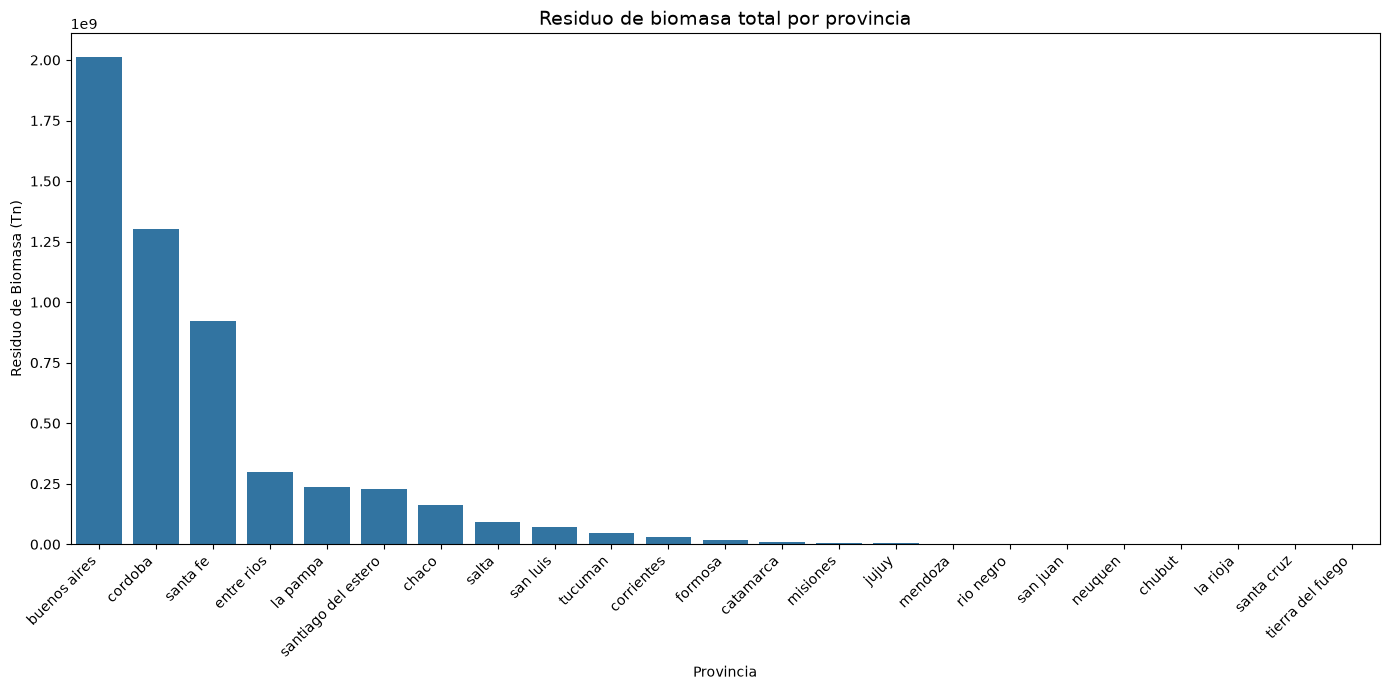

In [42]:
df_by_prov = (
    df_biomasa_validos
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa (Tn)", "Produccion (Tn)"]]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(data=df_by_prov, x="Provincia", y="Residuo de Biomasa (Tn)",
            order=df_by_prov["Provincia"])
plt.xticks(rotation=45, ha="right")
plt.title("Residuo de biomasa total por provincia", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn)")
plt.tight_layout()
plt.show()

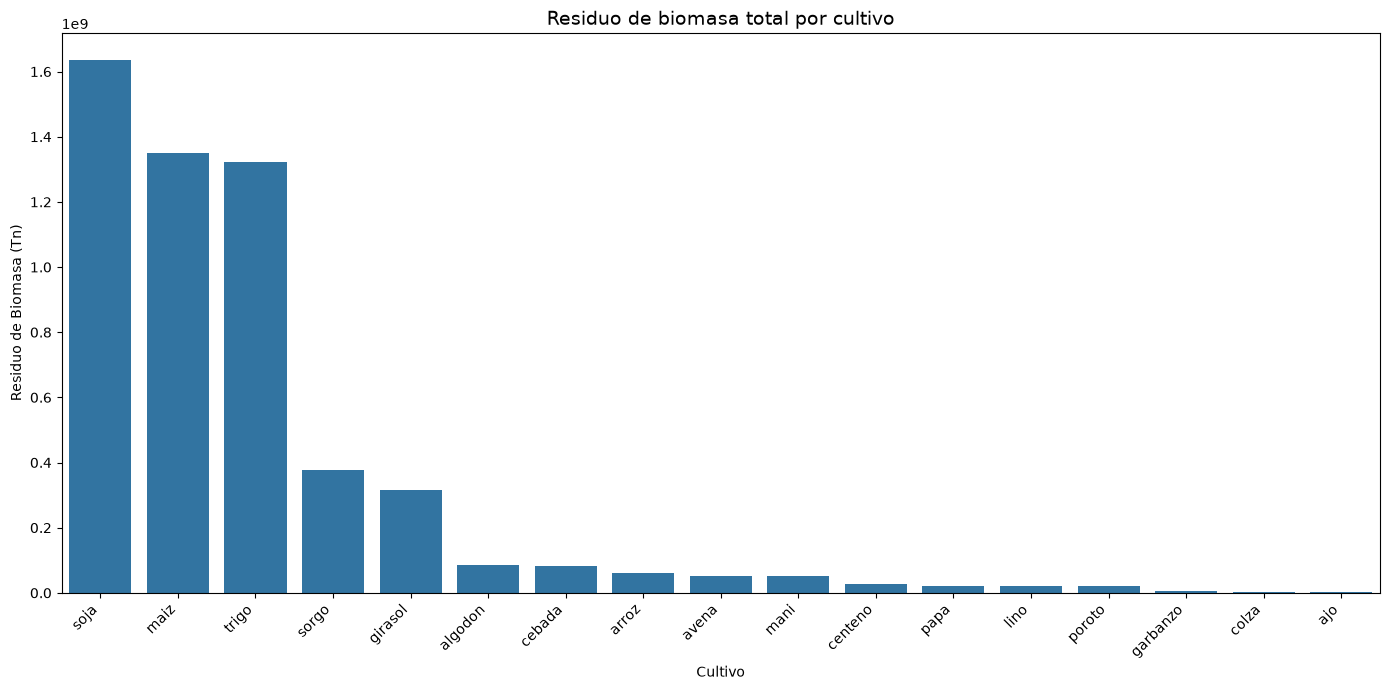

In [43]:
df_by_cultivo = (
    df_biomasa_validos
    .groupby("Cultivo", as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(data=df_by_cultivo, x="Cultivo", y="Residuo de Biomasa (Tn)",
            order=df_by_cultivo["Cultivo"])
plt.xticks(rotation=45, ha="right")
plt.title("Residuo de biomasa total por cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn)")
plt.tight_layout()
plt.show()

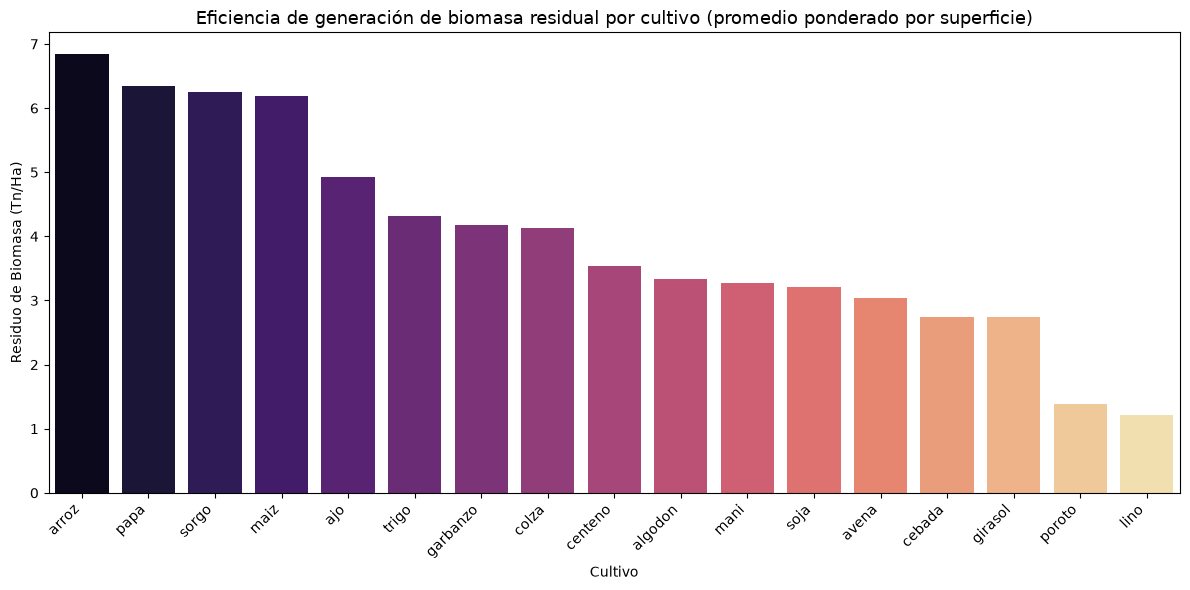

In [44]:
df_efficiency = (
    df_biomasa_validos
    .groupby("Cultivo", as_index=False)
    .apply(lambda g: pd.Series({
        "Residuo de Biomasa (Tn/Ha)": g["Residuo de Biomasa (Tn)"].sum() / g["Superficie (Ha)"].sum(),
    }))
    .reset_index(drop=True)
    .sort_values("Residuo de Biomasa (Tn/Ha)", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_efficiency, x="Cultivo", y="Residuo de Biomasa (Tn/Ha)",
            hue="Cultivo", palette="magma", legend=False, order=df_efficiency["Cultivo"])
plt.xticks(rotation=45, ha="right")
plt.title("Eficiencia de generación de biomasa residual por cultivo (promedio ponderado por superficie)", fontsize=13)
plt.ylabel("Residuo de Biomasa (Tn/Ha)")
plt.tight_layout()
plt.show()

### Top 30 Departamentos con mas Residuo de biomasa

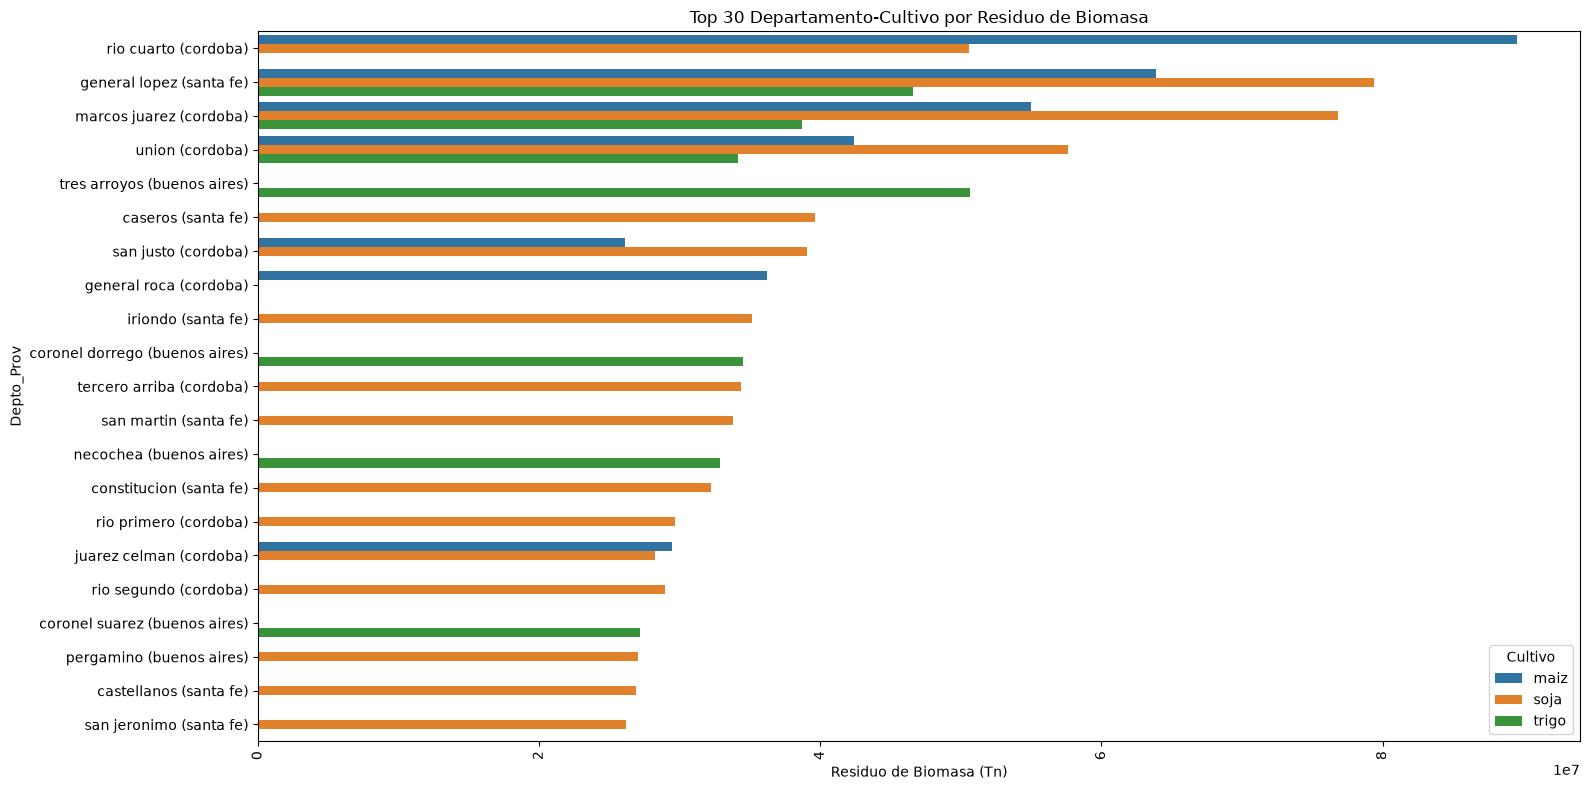

In [45]:
df_plot = (
    df_biomasa_validos
    .groupby(["Provincia", "Departamento", "Cultivo"], as_index=False)
    ["Residuo de Biomasa (Tn)"]
    .sum()
)

df_plot["Depto_Prov"] = (
    df_plot["Departamento"] +
    " (" +
    df_plot["Provincia"] +
    ")"
)

top30 = df_plot.nlargest(30, "Residuo de Biomasa (Tn)")

plt.figure(figsize=(16, 8))

sns.barplot(
    data=top30,
    x="Residuo de Biomasa (Tn)",
    y="Depto_Prov",
    hue="Cultivo"
)

plt.xticks(rotation=90)
plt.title("Top 30 Departamento-Cultivo por Residuo de Biomasa")
plt.tight_layout()
plt.show()

# 5. Persistencia de resultados

Se persisten el dataset curado y los artefactos de auditoría para permitir reproducción y análisis posterior.

In [46]:
audit_dir = Path("./../data/audit")
audit_dir.mkdir(parents=True, exist_ok=True)

audit = cmp.copy()
audit["diff_rel_produccion"] = audit[("Produccion (Tn)", "diff_rel")]
audit.to_parquet(audit_dir / "discrepancias_cba_vs_magyp.parquet")
df_descartado.to_parquet(audit_dir / "descartados_reconciliacion.parquet")
df_biomasa_validos.to_parquet(audit_dir / "biomasa_validos.parquet")

print("Artefactos de auditoría persistidos en", audit_dir.resolve())

Artefactos de auditoría persistidos en C:\dev\scrapper-BiomasaResidual\data\audit


# 6. Síntesis de hallazgos y limitaciones

## 6.1 Acciones implementadas y su impacto medido

| Acción | Hallazgo | Impacto medido |
|--------|----------|----------------|
| A1 — Normalización léxica | H2 | Reducción del dominio de cultivos a nombres canónicos unificados. |
| A2 — Taxonomía | H3 | 33 cultivos canónicos definidos con marca de agregado. |
| A3 — Normalización geográfica | H4 | Provincias y departamentos unificados entre fuentes. |
| A4 — Resolución agregados | H3 | Eliminación de doble conteo interno por fuente. |
| A5 — Reconciliación multi-fuente | H1 | Política de prioridad por producción aplicada sobre claves solapadas. |
| A6 — Limpieza CBA | H5 | Eliminación de columnas con cobertura 5%. |
| A7 — Conversión numérica | H6 | Reporte de valores coercidos por columna. |
| A8 — Flags de validez | H7 | Cobertura del análisis de biomasa cuantificada explícitamente. |

## 6.2 Limitaciones metodológicas reconocidas

1. **Cobertura geográfica asimétrica**: MAGYP cubre 23 provincias; CBA cubre 7 y actúa como fuente complementaria cuando MAGYP no reporta.
2. **IC asumido constante por cultivo**: sin ajuste por genética, prácticas agronómicas o variabilidad regional.
3. **Cultivos sin IC documentado excluidos**: caña de azúcar, yerba mate, cítricos y otros quedan fuera del análisis. Esto subrepresenta geográficamente al NOA y NEA, y se reporta explícitamente en la sección 4.4.
4. **Reconciliación por mayor producción**: la política asume que la mayor magnitud declarada es la más representativa del potencial productivo. En ausencia de validación contra *ground truth*, este criterio preserva la magnitud máxima reportada como estrategia conservadora.
5. **Filtro de validez explícito**: el descarte de filas se realiza por flag `_valido_biomasa`, no por `dropna` global, permitiendo cuantificar la cobertura del análisis.